# 02 — Bronze EDA | Panier Vert

**Objectif :** approfondir l'exploration des données brutes sans modifier les fichiers de `data/raw`.

Ce notebook étudie :
1. les valeurs manquantes (parcours complet des fichiers, par lots) ;
2. les distributions (sur échantillons) ;
3. les doublons (sur échantillons, avec gestion des listes et valeurs imbriquées) ;
4. les anomalies métier simples (sur échantillons).

**Important :** les contrôles calculés sur échantillons ne constituent pas une preuve d'absence d'anomalies dans l'ensemble du jeu de données. Les contrôles complets et les règles de qualité seront formalisés ensuite, notamment dans `04_silver_validation.ipynb`.

Les fichiers sources restent en lecture seule. Les rapports produits, si vous activez leur export, seront enregistrés dans `data/reports/bronze_eda/`.

## 0 — Préparation de l'environnement

Exécutez les cellules dans l'ordre. Le notebook recherche automatiquement la racine du projet à partir du dossier courant.

In [12]:
from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

# Recherche de la racine du projet
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p for p in candidates if (p / "data" / "raw").exists() and (p / "src").exists()),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        "Racine du projet introuvable. Placez le notebook dans le projet "
        "ou adaptez manuellement ROOT."
    )

BRONZE_DIR = ROOT / "data" / "raw"
REPORT_DIR = ROOT / "data" / "reports" / "bronze_eda"

print("Racine :", ROOT)
print("Bronze :", BRONZE_DIR)
print("Python :", __import__("sys").executable)
print("Pandas :", pd.__version__)

Racine : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert
Bronze : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert\data\raw
Python : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert\.venv\Scripts\python.exe
Pandas : 3.1.1


## 1 — Inventaire des fichiers Parquet

On exclut les dossiers techniques `_smoke` et `_runs` : ils ne font pas partie des jeux de données métier à profiler.

In [13]:
parquet_files = sorted(
    p for p in BRONZE_DIR.rglob("*.parquet")
    if "_smoke" not in p.parts and "_runs" not in p.parts
)

inventory = []
for path in parquet_files:
    pf = pq.ParquetFile(path)
    inventory.append({
        "source": path.parent.name,
        "fichier": path.name,
        "chemin": str(path.relative_to(ROOT)),
        "lignes": pf.metadata.num_rows,
        "colonnes": len(pf.schema.names),
        "taille_Mo": round(path.stat().st_size / (1024 ** 2), 2),
    })

inventory_df = pd.DataFrame(inventory)
display(inventory_df)
print(f"Fichiers : {len(inventory_df)} | Lignes : {inventory_df['lignes'].sum():,}")

,source,fichier,chemin,lignes,colonnes,taille_Mo
0,instacart,aisles.parquet,data\raw\instacart\aisles.parquet,134,2,0.00
1,instacart,departments.parquet,data\raw\instacart\departments.parquet,21,2,0.00
2,instacart,order_products__prior.parquet,data\raw\instacart\order_products__prior.parquet,32434489,4,125.81
3,instacart,order_products__train.parquet,data\raw\instacart\order_products__train.parquet,1384617,4,5.37
4,instacart,orders.parquet,data\raw\instacart\orders.parquet,3421083,7,31.60
5,instacart,products.parquet,data\raw\instacart\products.parquet,49688,4,1.45
6,openfoodfacts,products_20261117.parquet,data\raw\openfoodfacts\products_20261117.parquet,1000,15,0.21
7,rappelconso,rappelconso.parquet,data\raw\rappelconso\rappelconso.parquet,19018,37,4.36
8,scraping,articles_20261117.parquet,data\raw\scraping\articles_20261117.parquet,7,13,0.05


Fichiers : 9 | Lignes : 37,310,057


## 2 — Échantillons pour les analyses exploratoires

Les fichiers volumineux ne sont pas chargés intégralement en mémoire. Cette cellule lit au maximum `SAMPLE_LIMIT` lignes par fichier, par lots.

**Limite méthodologique :** il s'agit d'un échantillon de début de fichier, pratique pour une première EDA mais pas nécessairement représentatif de toutes les périodes ou catégories. Les conclusions sur les distributions et les doublons doivent donc être interprétées avec prudence.

In [14]:
SAMPLE_LIMIT = 50_000
BATCH_SIZE = 25_000

samples = {}
for path in parquet_files:
    pf = pq.ParquetFile(path)
    parts = []
    collected = 0

    for batch in pf.iter_batches(batch_size=BATCH_SIZE):
        frame = batch.to_pandas()
        remaining = SAMPLE_LIMIT - collected
        if len(frame) > remaining:
            frame = frame.iloc[:remaining]
        parts.append(frame)
        collected += len(frame)
        if collected >= SAMPLE_LIMIT:
            break

    samples[path.name] = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    print(f"{path.name}: {len(samples[path.name]):,} lignes échantillonnées")

aisles.parquet: 134 lignes échantillonnées
departments.parquet: 21 lignes échantillonnées
order_products__prior.parquet: 50,000 lignes échantillonnées
order_products__train.parquet: 50,000 lignes échantillonnées
orders.parquet: 50,000 lignes échantillonnées
products.parquet: 49,688 lignes échantillonnées
products_20261117.parquet: 1,000 lignes échantillonnées
rappelconso.parquet: 19,018 lignes échantillonnées
articles_20261117.parquet: 7 lignes échantillonnées


## 3 — Profil complet des valeurs manquantes

Cette section parcourt **toutes les lignes** par lots. Elle ne conserve pas le fichier entier en mémoire.

In [15]:

# 03 - Profil complet des valeurs manquantes
# Parcours de tous les fichiers par lots, sans charger les fichiers entiers.

missing_rows = []

for path in parquet_files:
    pf = pq.ParquetFile(path)
    total_rows = pf.metadata.num_rows

    # Initialisation à partir du schéma Parquet
    missing_counts = {name: 0 for name in pf.schema_arrow.names}
    scanned_rows = 0

    for batch in pf.iter_batches(batch_size=BATCH_SIZE):
        frame = batch.to_pandas()
        scanned_rows += len(frame)

        # On utilise les colonnes réellement présentes dans le lot
        for col in frame.columns:
            count = int(frame[col].isna().sum())
            missing_counts[col] = missing_counts.get(col, 0) + count

    # Construction du rapport
    for col, count in missing_counts.items():
        missing_rows.append({
            "source": path.parent.name,
            "fichier": path.name,
            "colonne": col,
            "valeurs_manquantes": count,
            "lignes_totales": total_rows,
            "pourcentage_manquant": (
                round(100 * count / total_rows, 2)
                if total_rows else 0
            )
        })

    print(f"{path.name} : {scanned_rows:,} lignes analysées")

missing_df = pd.DataFrame(missing_rows).sort_values(
    ["fichier", "pourcentage_manquant"],
    ascending=[True, False]
)

display(missing_df)


aisles.parquet : 134 lignes analysées
departments.parquet : 21 lignes analysées
order_products__prior.parquet : 32,434,489 lignes analysées
order_products__train.parquet : 1,384,617 lignes analysées
orders.parquet : 3,421,083 lignes analysées
products.parquet : 49,688 lignes analysées
products_20261117.parquet : 1,000 lignes analysées
rappelconso.parquet : 19,018 lignes analysées
articles_20261117.parquet : 7 lignes analysées


,source,fichier,colonne,valeurs_manquantes,lignes_totales,pourcentage_manquant
0,instacart,aisles.parquet,aisle_id,0,134,0.00
1,instacart,aisles.parquet,aisle,0,134,0.00
77,scraping,articles_20261117.parquet,published,7,7,100.00
78,scraping,articles_20261117.parquet,updated,2,7,28.57
75,scraping,articles_20261117.parquet,url,0,7,0.00
...,...,...,...,...,...,...
70,rappelconso,rappelconso.parquet,date_publication,0,19018,0.00
71,rappelconso,rappelconso.parquet,libelle,0,19018,0.00
72,rappelconso,rappelconso.parquet,id,0,19018,0.00
73,rappelconso,rappelconso.parquet,_source,0,19018,0.00


,source,fichier,colonne,valeurs_manquantes,lignes_totales,pourcentage_manquant
77,scraping,articles_20261117.parquet,published,7,7,100.00
78,scraping,articles_20261117.parquet,updated,2,7,28.57
18,instacart,orders.parquet,days_since_prior_order,206209,3421083,6.03
29,openfoodfacts,products_20261117.parquet,nutriscore_score,30,1000,3.00
31,openfoodfacts,products_20261117.parquet,nova_group,17,1000,1.70
24,openfoodfacts,products_20261117.parquet,product_name,1,1000,0.10
25,openfoodfacts,products_20261117.parquet,brands,1,1000,0.10
32,openfoodfacts,products_20261117.parquet,ingredients_text,1,1000,0.10
65,rappelconso,rappelconso.parquet,lien_vers_la_liste_des_produits,14598,19018,76.76
63,rappelconso,rappelconso.parquet,informations_complementaires_publiques,14513,19018,76.31


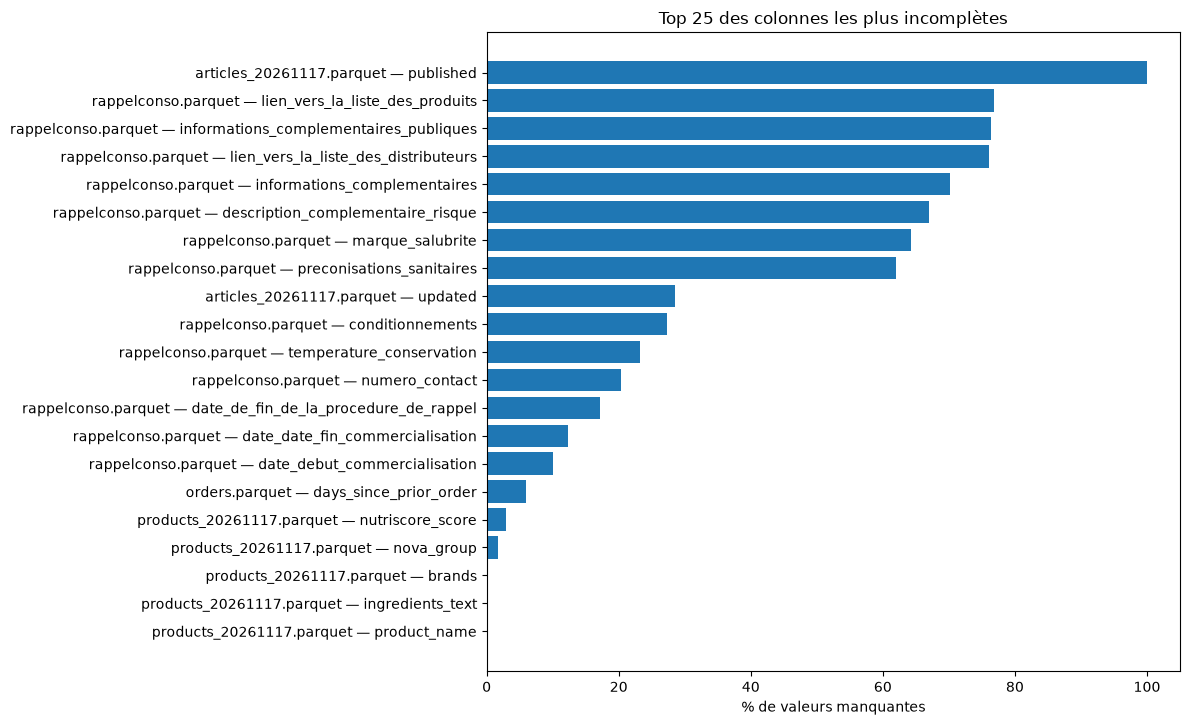

In [16]:
# Colonnes avec au moins une valeur manquante
missing_nonzero = missing_df[missing_df["valeurs_manquantes"] > 0].copy()
display(missing_nonzero)

# Visualisation : top 25 des colonnes les plus manquantes en pourcentage
top_missing = missing_nonzero.sort_values(
    "pourcentage_manquant", ascending=False
).head(25)

if not top_missing.empty:
    labels = top_missing["fichier"] + " — " + top_missing["colonne"]
    plt.figure(figsize=(12, max(5, len(top_missing) * 0.35)))
    plt.barh(labels[::-1], top_missing["pourcentage_manquant"][::-1])
    plt.xlabel("% de valeurs manquantes")
    plt.title("Top 25 des colonnes les plus incomplètes")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune valeur manquante détectée.")

## 4 — Distributions et statistiques descriptives (échantillons)

Les statistiques numériques et les fréquences catégorielles ci-dessous sont calculées sur les échantillons, pas sur l'intégralité des fichiers.

In [17]:
for file_name, frame in samples.items():
    print("\n" + "=" * 90)
    print(f"{file_name} — {len(frame):,} lignes échantillonnées")

    if frame.empty:
        print("Échantillon vide.")
        continue

    numeric_cols = frame.select_dtypes(include="number").columns.tolist()
    if numeric_cols:
        print("\nStatistiques numériques :")
        display(frame[numeric_cols].describe().T)

    categorical_cols = [
        c for c in frame.columns
        if c not in numeric_cols and frame[c].dtype == "object"
    ]
    for col in categorical_cols[:8]:
        print(f"\nValeurs les plus fréquentes — {col}")
        display(frame[col].value_counts(dropna=False).head(10).rename("effectif").to_frame())


aisles.parquet — 134 lignes échantillonnées

Statistiques numériques :


,count,mean,std,min,25%,50%,75%,max
aisle_id,134.0,67.5,38.826537,1.0,34.25,67.5,100.75,134.0



departments.parquet — 21 lignes échantillonnées

Statistiques numériques :


,count,mean,std,min,25%,50%,75%,max
department_id,21.0,11.0,6.204837,1.0,6.0,11.0,16.0,21.0



order_products__prior.parquet — 50,000 lignes échantillonnées

Statistiques numériques :


,count,mean,std,min,25%,50%,75%,max
order_id,50000.0,2623.43574,1522.631441,2.0,1292.0,2612.0,3932.00,5281.0
product_id,50000.0,25638.99736,14124.956385,1.0,13560.0,25272.0,38153.25,49683.0
add_to_cart_order,50000.0,8.16048,6.788011,1.0,3.0,6.0,11.00,61.0
reordered,50000.0,0.59892,0.490122,0.0,0.0,1.0,1.00,1.0


... (16 outputs left out)


rappelconso.parquet — 19,018 lignes échantillonnées

Statistiques numériques :


,count,mean,std,min,25%,50%,75%,max
gtin,19018.0,7.506720e+13,2.175252e+15,0.0,3.250391e+12,3.428881e+12,3.760004e+12,9.915900e+16
numero_version,19018.0,1.078610e+00,3.027870e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00
id,19018.0,1.246909e+04,7.165490e+03,21.0,5.817250e+03,1.286700e+04,1.885550e+04,2.409700e+04



articles_20261117.parquet — 7 lignes échantillonnées

Valeurs les plus fréquentes — published


,effectif
published,
None,7


## 5 — Contrôle préliminaire des doublons (échantillons)

Certaines colonnes contiennent des listes ou des structures imbriquées. Pour éviter l'erreur `TypeError: unhashable type`, on convertit temporairement les valeurs complexes en représentations stables avant de rechercher les lignes identiques.

**Attention :** ce contrôle ne porte que sur les échantillons. Il ne prouve pas l'absence de doublons dans les fichiers complets.

In [18]:
def canonical_value(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple, dict, set)):
        if isinstance(value, set):
            value = sorted(value, key=lambda x: str(x))
        return json.dumps(value, ensure_ascii=False, sort_keys=True, default=str)
    if isinstance(value, (np.integer, np.floating, np.bool_)):
        return value.item()
    return value

duplicate_rows = []

for file_name, frame in samples.items():
    if frame.empty:
        duplicate_count = 0
    else:
        comparable = frame.copy()
        for col in comparable.columns:
            if comparable[col].dtype == "object":
                comparable[col] = comparable[col].map(canonical_value)
        duplicate_count = int(comparable.duplicated().sum())

    duplicate_rows.append({
        "fichier": file_name,
        "lignes_echantillon": len(frame),
        "doublons_exacts_echantillon": duplicate_count,
        "pourcentage_doublons_echantillon": (
            round(100 * duplicate_count / len(frame), 3) if len(frame) else 0
        )
    })

duplicates_df = pd.DataFrame(duplicate_rows)
display(duplicates_df)

,fichier,lignes_echantillon,doublons_exacts_echantillon,pourcentage_doublons_echantillon
0,aisles.parquet,134,0,0.0
1,departments.parquet,21,0,0.0
2,order_products__prior.parquet,50000,0,0.0
3,order_products__train.parquet,50000,0,0.0
4,orders.parquet,50000,0,0.0
5,products.parquet,49688,0,0.0
6,products_20261117.parquet,1000,0,0.0
7,rappelconso.parquet,19018,0,0.0
8,articles_20261117.parquet,7,0,0.0


## 6 — Contrôles métier préliminaires (échantillons)

Ces contrôles signalent des valeurs à examiner. Ils ne modifient aucune donnée et ne remplacent pas les règles de validation Silver.

In [19]:
anomaly_reports = []

def add_check(file_name, check_name, count, details):
    anomaly_reports.append({
        "fichier": file_name,
        "controle": check_name,
        "nombre_cas_echantillon": int(count),
        "detail": details,
    })

# Instacart : commandes
orders = samples.get("orders.parquet")
if orders is not None and not orders.empty:
    if "order_dow" in orders:
        bad = ~orders["order_dow"].dropna().between(0, 6)
        add_check("orders.parquet", "order_dow hors [0, 6]", bad.sum(),
                  "Valeurs attendues : entiers de 0 à 6.")
    if "order_hour_of_day" in orders:
        bad = ~orders["order_hour_of_day"].dropna().between(0, 23)
        add_check("orders.parquet", "order_hour_of_day hors [0, 23]", bad.sum(),
                  "Valeurs attendues : entiers de 0 à 23.")
    if "order_number" in orders:
        bad = orders["order_number"].dropna() < 1
        add_check("orders.parquet", "order_number inférieur à 1", bad.sum(),
                  "Le numéro de commande devrait commencer à 1.")
    if {"order_number", "days_since_prior_order"}.issubset(orders.columns):
        first_order_missing_interval = (
            orders["order_number"].eq(1) & orders["days_since_prior_order"].isna()
        ).sum()
        add_check("orders.parquet", "Première commande sans intervalle précédent",
                  first_order_missing_interval,
                  "Cas généralement attendu pour order_number = 1.")

# Instacart : lignes produits-commandes
for file_name in ["order_products__prior.parquet", "order_products__train.parquet"]:
    frame = samples.get(file_name)
    if frame is not None and not frame.empty:
        if "reordered" in frame:
            bad = ~frame["reordered"].dropna().isin([0, 1])
            add_check(file_name, "reordered hors {0, 1}", bad.sum(),
                      "Valeurs attendues : 0 ou 1.")
        if "add_to_cart_order" in frame:
            bad = frame["add_to_cart_order"].dropna() < 1
            add_check(file_name, "add_to_cart_order inférieur à 1", bad.sum(),
                      "La position dans le panier devrait être positive.")

# Open Food Facts : catégories de scores / groupes
off_name = "products_20261117.parquet"
off = samples.get(off_name)
if off is not None and not off.empty:
    if "nutriscore_grade" in off:
        values = off["nutriscore_grade"].dropna().astype(str).str.lower()
        bad = ~values.isin(list("abcde") + ["not-applicable", "unknown", ""])
        add_check(off_name, "nutriscore_grade hors modalités usuelles", bad.sum(),
                  "À examiner : grades a-e et éventuelles modalités particulières.")
    if "nova_group" in off:
        values = pd.to_numeric(off["nova_group"], errors="coerce").dropna()
        bad = ~values.isin([1, 2, 3, 4])
        add_check(off_name, "nova_group hors 1-4", bad.sum(),
                  "Valeurs NOVA numériques attendues : 1 à 4.")

# Scraping : dates et titres
articles = samples.get("articles_20261117.parquet")
if articles is not None and not articles.empty:
    if "published" in articles:
        add_check("articles_20261117.parquet", "published manquant",
                  articles["published"].isna().sum(),
                  "Comparer avec published_text, updated et date_reference.")
    if "title" in articles:
        generic = articles["title"].astype("string").str.strip().str.lower().eq("paramètres d'affichage")
        add_check("articles_20261117.parquet", "Titre générique 'Paramètres d'affichage'",
                  generic.sum(),
                  "Vérifier l'extraction du véritable titre éditorial.")

anomalies_df = pd.DataFrame(anomaly_reports)
display(anomalies_df)

,fichier,controle,nombre_cas_echantillon,detail
0,orders.parquet,"order_dow hors [0, 6]",0,Valeurs attendues : entiers de 0 à 6.
1,orders.parquet,"order_hour_of_day hors [0, 23]",0,Valeurs attendues : entiers de 0 à 23.
2,orders.parquet,order_number inférieur à 1,0,Le numéro de commande devrait commencer à 1.
3,orders.parquet,Première commande sans intervalle précédent,3106,Cas généralement attendu pour order_number = 1.
4,order_products__prior.parquet,"reordered hors {0, 1}",0,Valeurs attendues : 0 ou 1.
5,order_products__prior.parquet,add_to_cart_order inférieur à 1,0,La position dans le panier devrait être positive.
6,order_products__train.parquet,"reordered hors {0, 1}",0,Valeurs attendues : 0 ou 1.
7,order_products__train.parquet,add_to_cart_order inférieur à 1,0,La position dans le panier devrait être positive.
8,products_20261117.parquet,nutriscore_grade hors modalités usuelles,0,À examiner : grades a-e et éventuelles modalités particulières.
9,products_20261117.parquet,nova_group hors 1-4,0,Valeurs NOVA numériques attendues : 1 à 4.


## 7 — Dates : aperçu des conversions possibles

On teste la conversion des colonnes de dates candidates sur les échantillons. Les valeurs d'origine ne sont pas modifiées.

In [20]:
date_candidates = {
    "orders.parquet": [],
    "products_20261117.parquet": ["_ingested_at"],
    "rappelconso.parquet": [
        "date_debut_commercialisation",
        "date_date_fin_commercialisation",
        "date_de_fin_de_la_procedure_de_rappel",
        "date_publication",
        "_ingested_at",
    ],
    "articles_20261117.parquet": [
        "updated", "published_text", "scraped_at", "date_reference", "_ingested_at"
    ],
}

date_report = []
for file_name, columns in date_candidates.items():
    frame = samples.get(file_name)
    if frame is None or frame.empty:
        continue
    for col in columns:
        if col not in frame.columns:
            continue
        parsed = pd.to_datetime(frame[col], errors="coerce", dayfirst=True, utc=True)
        non_missing = frame[col].notna().sum()
        failed = int((frame[col].notna() & parsed.isna()).sum())
        date_report.append({
            "fichier": file_name,
            "colonne": col,
            "valeurs_non_manquantes": int(non_missing),
            "conversions_en_echec": failed,
            "taux_echec_pct": round(100 * failed / non_missing, 2) if non_missing else 0,
        })

date_report_df = pd.DataFrame(date_report)
display(date_report_df)

C:\Users\HP\AppData\Local\Temp\ipykernel_14132\1926095403.py:24: UserWarning: Parsing dates in %Y-%m-%dT%H:%M:%S%z format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  parsed = pd.to_datetime(frame[col], errors="coerce", dayfirst=True, utc=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_14132\1926095403.py:24: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  parsed = pd.to_datetime(frame[col], errors="coerce", dayfirst=True, utc=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_14132\1926095403.py:24: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  parsed = pd.to_datetime(frame[col], errors="coerce", dayfirst=True, utc=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_14132\1926095403.py:24: UserWarning: Parsing dates in %Y-%m-%dT%H:%M:%S%

,fichier,colonne,valeurs_non_manquantes,conversions_en_echec,taux_echec_pct
0,products_20261117.parquet,_ingested_at,1000,0,0.00
1,rappelconso.parquet,date_debut_commercialisation,17116,8793,51.37
2,rappelconso.parquet,date_date_fin_commercialisation,16666,0,0.00
3,rappelconso.parquet,date_de_fin_de_la_procedure_de_rappel,15766,0,0.00
4,rappelconso.parquet,date_publication,19018,0,0.00
5,rappelconso.parquet,_ingested_at,19018,0,0.00
6,articles_20261117.parquet,updated,5,5,100.00
7,articles_20261117.parquet,published_text,7,7,100.00
8,articles_20261117.parquet,scraped_at,7,0,0.00
9,articles_20261117.parquet,date_reference,7,7,100.00


## 8 — Export facultatif des rapports

Cette cellule écrit uniquement des rapports CSV dans `data/reports/bronze_eda/`. Elle ne modifie jamais `data/raw`.

Laissez `EXPORT_REPORTS = False` si vous ne souhaitez pas encore créer ces fichiers.

In [21]:
EXPORT_REPORTS = True 

if EXPORT_REPORTS:
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    inventory_df.to_csv(REPORT_DIR / "inventory.csv", index=False, encoding="utf-8-sig")
    missing_df.to_csv(REPORT_DIR / "missing_values.csv", index=False, encoding="utf-8-sig")
    duplicates_df.to_csv(REPORT_DIR / "sample_duplicates.csv", index=False, encoding="utf-8-sig")
    anomalies_df.to_csv(REPORT_DIR / "sample_anomalies.csv", index=False, encoding="utf-8-sig")
    date_report_df.to_csv(REPORT_DIR / "date_conversion_checks.csv", index=False, encoding="utf-8-sig")
    print("Rapports enregistrés dans :", REPORT_DIR)
else:
    print("Export désactivé : aucun fichier de rapport n'a été créé.")

Rapports enregistrés dans : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert\data\reports\bronze_eda


## 9 — Conclusion de l'EDA Bronze

À la fin de l'exécution, compléter cette synthèse avec les résultats observés :

- Colonnes présentant le plus de valeurs manquantes :
- Colonnes numériques à distributions atypiques :
- Doublons exacts observés dans les échantillons :
- Anomalies métier à investiguer :
- Dates nécessitant une conversion ou une règle spécifique :
- Limites de l'échantillonnage :

**Décision :** ne pas nettoyer directement les fichiers Bronze. Les règles de correction et de normalisation seront appliquées dans la couche Silver, puis contrôlées dans `04_silver_validation.ipynb`.

In [22]:
from pathlib import Path
import sys
import pandas as pd
import pyarrow.parquet as pq
import tempfile

# Retrouver automatiquement la racine du projet
cwd = Path.cwd()
ROOT = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "src" / "panier_vert" / "storage" / "rustfs.py").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError("Impossible de retrouver la racine du projet.")

sys.path.insert(0, str(ROOT / "src"))

from panier_vert.storage.rustfs import s3, RUSTFS_BUCKET

print("Projet :", ROOT)
print("Bucket :", RUSTFS_BUCKET)
print("Connexion RustFS prête.")

Projet : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert
Bucket : panier-vert
Connexion RustFS prête.
